# AI4201 — Perceptron and ADALINE from Scratch

**Student ID:** [Student ID removed]  
**Course:** Machine Learning in Engineering  
**Random seed:** 42  
**Dataset:** [UCI Iris](https://archive.ics.uci.edu/dataset/53/iris)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
np.random.seed(42)

# Official UCI Iris source; fallback permits running without internet.
uci_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data"
columns = ["sepal length (cm)", "sepal width (cm)", "petal length (cm)", "petal width (cm)", "species"]
try:
    df = pd.read_csv(uci_url, header=None, names=columns).dropna(how="all")
    df["species"] = df["species"].str.replace("Iris-", "", regex=False).str.lower()
    print("Data source: UCI Iris official repository")
except Exception as exc:
    print("UCI download unavailable; using sklearn's packaged copy of the Iris dataset:", type(exc).__name__)
    iris = load_iris()
    df = pd.DataFrame(iris.data, columns=columns[:4])
    df["species"] = pd.Categorical.from_codes(iris.target, iris.target_names)

print("Shape:", df.shape)
print("\nData types:\n", df.dtypes)
print("\nClass counts:\n", df["species"].value_counts())
print("\nMissing values:\n", df.isnull().sum())
print("\nDescriptive statistics:\n", df.describe())

Data source: UCI Iris official repository
Shape: (150, 5)

Data types:
 sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
species               object
dtype: object

Class counts:
 species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

Missing values:
 sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Descriptive statistics:
        sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.054000           3.758667   
std             0.828066          0.433594           1.764420   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.30000

### Task 1: Dataset Documentation and Data Quality

**Dataset Source:** UCI Machine Learning Repository – Iris Dataset.

https://archive.ics.uci.edu/dataset/53/iris

**Feature Units:** All four flower measurements are recorded in centimeters (cm).

**Data Quality Risk:** Real-world sensors may produce inaccurate measurements due to calibration errors or sensor noise. These errors could affect the classification accuracy of the models.

**Source note:** The notebook first attempts the official UCI CSV download. When network access is unavailable, it transparently uses the packaged scikit-learn copy and reports the fallback. The final experiment should be rerun with internet access to demonstrate the official download.


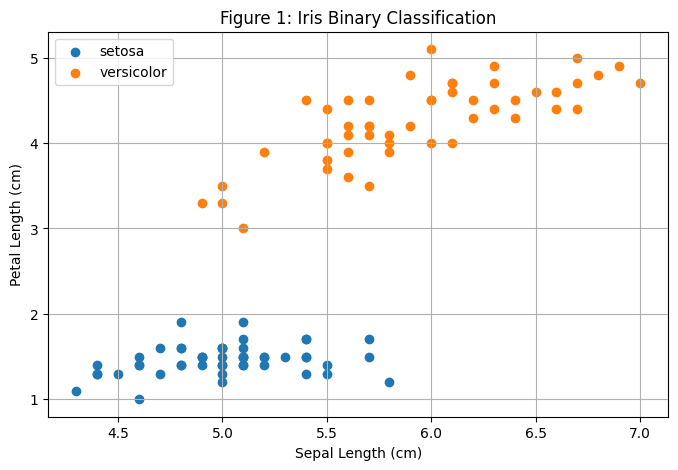

In [2]:

# Select only Setosa and Versicolor
binary_df = df[df["species"].isin(
    ["setosa", "versicolor"]
)].copy()

# Convert labels to -1 and +1
binary_df["label"] = binary_df["species"].map({
    "setosa": -1,
    "versicolor": 1
}).astype(int)

# Plot the two classes
plt.figure(figsize=(8, 5))

for species in ["setosa", "versicolor"]:
    subset = binary_df[binary_df["species"] == species]
    plt.scatter(
        subset["sepal length (cm)"],
        subset["petal length (cm)"],
        label=species
    )

plt.xlabel("Sepal Length (cm)")
plt.ylabel("Petal Length (cm)")
plt.title("Figure 1: Iris Binary Classification")
plt.legend()
plt.grid(True)
plt.show()


**Figure 1 interpretation:** The two classes are separated mainly along petal length; the plot displays centimeters on both axes.

In [3]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Select two features
X = binary_df[
    ["sepal length (cm)", "petal length (cm)"]
].values

y = binary_df["label"].values

# 70% training, 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Standardize features
scaler = StandardScaler()

X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training shape:", X_train_std.shape)


Training samples: 70
Testing samples: 30
Training shape: (70, 2)


### Task 2: Feature Scaling Discussion

ADALINE is generally more sensitive to feature scaling because it uses gradient descent to minimize squared error. Features with different scales can cause unstable or slow convergence. Standardization helps improve training stability.

The Perceptron can also be affected by feature scaling, especially in its convergence speed and update behavior.

In [4]:

# Task 3: Perceptron from Scratch

class PerceptronScratch:
    """Binary Perceptron classifier using NumPy."""

    def __init__(self, learning_rate=0.01,
                 max_epochs=50, random_seed=42):
        self.learning_rate = learning_rate
        self.max_epochs = max_epochs
        self.random_seed = random_seed

    def net_input(self, X):
        return np.dot(X, self.weights_) + self.bias_

    def predict(self, X):
        z = self.net_input(X)
        return np.where(z >= 0, 1, -1)

    def fit(self, X, y):
        rng = np.random.RandomState(self.random_seed)

        self.weights_ = rng.normal(
            loc=0.0, scale=0.01, size=X.shape[1]
        )
        self.bias_ = 0.0
        self.errors_ = []

        for epoch in range(self.max_epochs):
            for xi, target in zip(X, y):
                prediction = self.predict(xi)
                update = self.learning_rate * (
                    target - prediction
                )

                self.weights_ += update * xi
                self.bias_ += update

            # Count errors after each epoch
            errors = np.sum(self.predict(X) != y)
            self.errors_.append(int(errors))

        return self


Weights: [0.00595798 0.04291947]
Bias: 0.02
Final training errors: 0


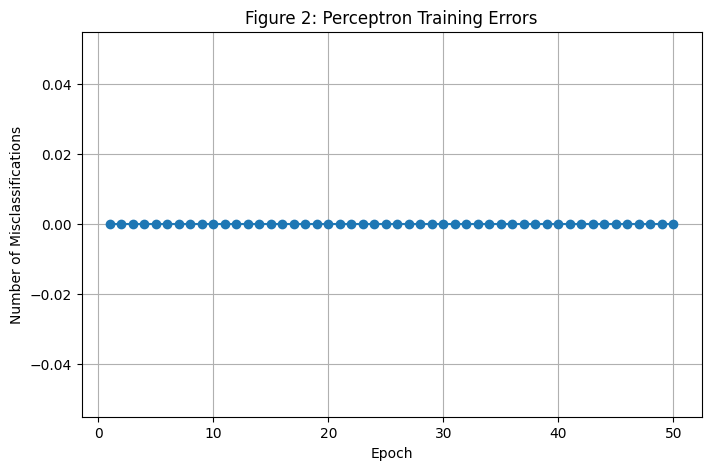

In [5]:

# Train Perceptron on standardized data
perceptron = PerceptronScratch(
    learning_rate=0.01,
    max_epochs=50,
    random_seed=42
)

perceptron.fit(X_train_std, y_train)

print("Weights:", perceptron.weights_)
print("Bias:", perceptron.bias_)
print("Final training errors:", perceptron.errors_[-1])

# Plot training errors
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, 51),
    perceptron.errors_,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Number of Misclassifications")
plt.title("Figure 2: Perceptron Training Errors")
plt.grid(True)
plt.show()


In [6]:

# Verify one Perceptron update

x_sample = np.array([1.0, 2.0])
y_true = 1

initial_weights = np.array([0.0, 0.0])
initial_bias = -1.0
eta = 0.01

z = np.dot(initial_weights, x_sample) + initial_bias
y_pred = 1 if z >= 0 else -1

update = eta * (y_true - y_pred)

new_weights = initial_weights + update * x_sample
new_bias = initial_bias + update

print("Prediction:", y_pred)
print("Update:", update)
print("New weights:", new_weights)
print("New bias:", new_bias)

# Verify against the class update rule
model = PerceptronScratch(learning_rate=eta)
model.weights_ = initial_weights.copy()
model.bias_ = initial_bias

code_prediction = model.predict(x_sample)
code_update = eta * (y_true - code_prediction)
model.weights_ += code_update * x_sample
model.bias_ += code_update

assert np.allclose(model.weights_, new_weights)
assert np.isclose(model.bias_, new_bias)
print("Verification passed!")


Prediction: -1
Update: 0.02
New weights: [0.02 0.04]
New bias: -0.98
Verification passed!


### Task 3: Manual Perceptron Update

Given:

- Input: x = [1, 2]
- True label: y = +1
- Initial weights: w = [0, 0]
- Initial bias: b = -1
- Learning rate: η = 0.01

**Step 1: Calculate net input**

z = (0 × 1) + (0 × 2) − 1 = −1

Since z < 0, the predicted label is −1.

**Step 2: Calculate update**

η(y − ŷ) = 0.01 × (1 − (−1)) = 0.02

**Step 3: Update weights and bias**

w_new = [0, 0] + 0.02 × [1, 2] = [0.02, 0.04]

b_new = −1 + 0.02 = −0.98

The manual calculation matches the NumPy implementation.

In [7]:

# Task 4: ADALINE from Scratch

class AdalineGDScratch:
    """ADALINE using batch gradient descent."""

    def __init__(self, learning_rate=0.01,
                 max_epochs=50, random_seed=42):
        self.learning_rate = learning_rate
        self.max_epochs = max_epochs
        self.random_seed = random_seed

    def net_input(self, X):
        return np.dot(X, self.weights_) + self.bias_

    def predict(self, X):
        return np.where(self.net_input(X) >= 0, 1, -1)

    def fit(self, X, y):
        rng = np.random.RandomState(self.random_seed)

        self.weights_ = rng.normal(
            loc=0.0, scale=0.01, size=X.shape[1]
        )
        self.bias_ = 0.0
        self.cost_ = []

        n = len(y)

        for epoch in range(self.max_epochs):
            z = self.net_input(X)
            errors = y - z

            # Batch gradient descent
            self.weights_ += (
                self.learning_rate *
                X.T.dot(errors) / n
            )
            self.bias_ += (
                self.learning_rate * errors.mean()
            )

            # Calculate MSE after the update
            new_errors = y - self.net_input(X)
            mse = np.mean(new_errors ** 2)

            if not np.isfinite(mse):
                raise FloatingPointError(
                    f"Non-finite cost at epoch {epoch + 1}"
                )

            self.cost_.append(float(mse))

        return self


Weights: [0.23668382 0.33342847]
Bias: 8.491620105490125e-17
Final MSE: 0.29325183444388186


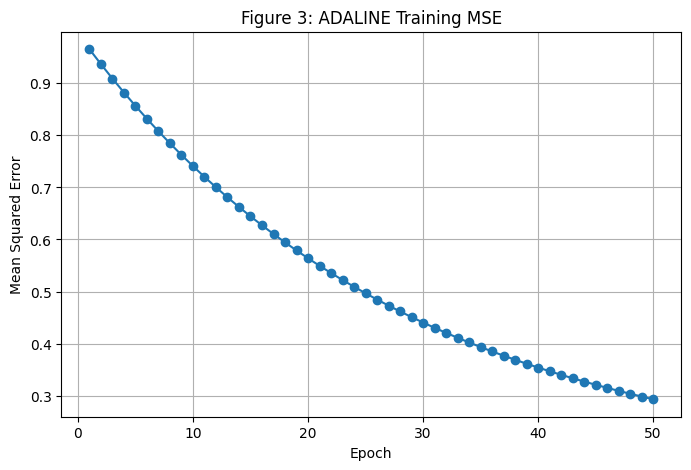

In [8]:

# Train ADALINE

adaline = AdalineGDScratch(
    learning_rate=0.01,
    max_epochs=50,
    random_seed=42
)

adaline.fit(X_train_std, y_train)

print("Weights:", adaline.weights_)
print("Bias:", adaline.bias_)
print("Final MSE:", adaline.cost_[-1])

# Plot MSE history
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, 51),
    adaline.cost_,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Figure 3: ADALINE Training MSE")
plt.grid(True)
plt.show()


In [9]:

# Manual ADALINE batch update verification

X_small = np.array([
    [1.0, 2.0],
    [2.0, 1.0]
])

y_small = np.array([1, -1])

w = np.array([0.0, 0.0])
b = 0.0
eta = 0.1

# Manual calculation
z = X_small @ w + b
errors = y_small - z

w_new = w + eta * (X_small.T @ errors) / len(y_small)
b_new = b + eta * errors.mean()

print("Updated weights:", w_new)
print("Updated bias:", b_new)

# Verify against one epoch of the class
model = AdalineGDScratch(
    learning_rate=eta,
    max_epochs=1,
    random_seed=42
)

# Use the same initial parameters
# and apply the class's batch update formula
model.weights_ = w.copy()
model.bias_ = b

model_errors = y_small - model.net_input(X_small)

model.weights_ += eta * (
    X_small.T @ model_errors
) / len(y_small)

model.bias_ += eta * model_errors.mean()

assert np.allclose(model.weights_, w_new)
assert np.isclose(model.bias_, b_new)

print("Verification passed!")


Updated weights: [-0.05  0.05]
Updated bias: 0.0
Verification passed!


In [10]:

# Verify the actual fit() method

check = AdalineGDScratch(
    learning_rate=eta,
    max_epochs=1,
    random_seed=42
)

rng = np.random.RandomState(42)
initial_w = rng.normal(0.0, 0.01, X_small.shape[1])

initial_errors = y_small - X_small @ initial_w

expected_w = initial_w + eta * (
    X_small.T @ initial_errors
) / len(y_small)

expected_b = eta * initial_errors.mean()

check.fit(X_small, y_small)

assert np.allclose(check.weights_, expected_w)
assert np.isclose(check.bias_, expected_b)

print("fit() verification passed!")


fit() verification passed!


### Task 4: ADALINE Manual Batch Update

The ADALINE model uses batch gradient descent to minimize squared error.

For the manual example:

- X = [[1, 2], [2, 1]]
- y = [1, -1]
- Initial weights = [0, 0]
- Initial bias = 0
- Learning rate = 0.1

**Step 1: Calculate linear outputs**

z = [0, 0]

**Step 2: Calculate errors**

y − z = [1, −1]

**Step 3: Update weights**

Xᵀ(y − z) = [−1, 1]

w_new = [0, 0] + (0.1 / 2) × [−1, 1]

w_new = [−0.05, 0.05]

**Step 4: Update bias**

b_new = 0 + 0.1 × (1 − 1) / 2 = 0

The manual batch update matches the NumPy gradient calculation. The implementation is also tested using a one-epoch fit with its seeded initial weights.

Unlike Perceptron, ADALINE uses the continuous linear output during training and applies the classification threshold only during prediction.

In [11]:

# Task 5: Controlled Training Experiments

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

experiments = {}
results = []

# Perceptron experiments
for name, X_data in [
    ("P1_Raw", X_train),
    ("P2_Standardized", X_train_std)
]:
    model = PerceptronScratch(
        learning_rate=0.01,
        max_epochs=50,
        random_seed=42
    )
    model.fit(X_data, y_train)

    experiments[name] = model

    results.append({
        "Run": name,
        "Model": "Perceptron",
        "Learning Rate": 0.01,
        "Final Training Error": model.errors_[-1],
        "Final MSE": np.nan,
        "Status": "Completed"
    })

# ADALINE experiments
for data_name, X_data in [
    ("Raw", X_train),
    ("Standardized", X_train_std)
]:
    for lr in [0.1, 0.01, 0.001]:
        name = f"A_{data_name}_{lr}"

        model = AdalineGDScratch(
            learning_rate=lr,
            max_epochs=50,
            random_seed=42
        )

        try:
            model.fit(X_data, y_train)
            status = "Completed"
            final_mse = model.cost_[-1]
        except (FloatingPointError, OverflowError):
            status = "Diverged"
            final_mse = np.nan

        experiments[name] = model

        results.append({
            "Run": name,
            "Model": "ADALINE",
            "Learning Rate": lr,
            "Final Training Error": np.nan,
            "Final MSE": final_mse,
            "Status": status
        })

results_df = pd.DataFrame(results)
print("Table 1: Controlled experiment summary")
display(results_df)


Table 1: Controlled experiment summary


,Run,Model,Learning Rate,Final Training Error,Final MSE,Status
0,P1_Raw,Perceptron,0.010,0.0,NaN,Completed
1,P2_Standardized,Perceptron,0.010,0.0,NaN,Completed
2,A_Raw_0.1,ADALINE,0.100,NaN,5.020893e+46,Completed
3,A_Raw_0.01,ADALINE,0.010,NaN,3.763493e-01,Completed
4,A_Raw_0.001,ADALINE,0.001,NaN,8.866398e-01,Completed
5,A_Standardized_0.1,ADALINE,0.100,NaN,7.525961e-02,Completed
6,A_Standardized_0.01,ADALINE,0.010,NaN,2.932518e-01,Completed
7,A_Standardized_0.001,ADALINE,0.001,NaN,8.575501e-01,Completed


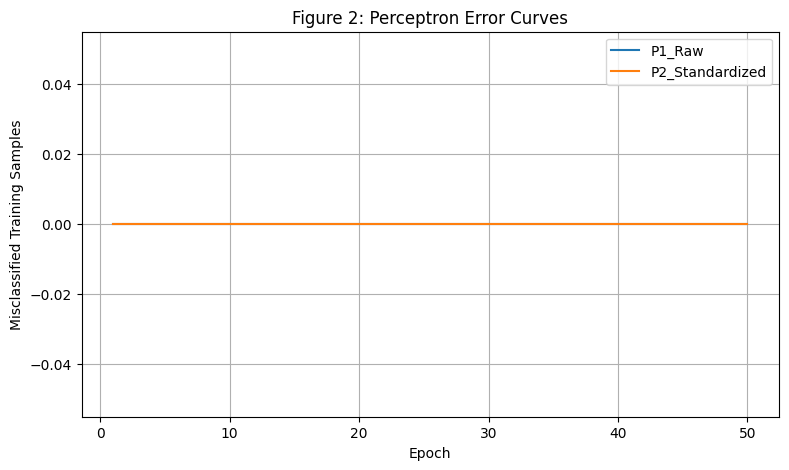

In [12]:

# Figure 2: Perceptron Error Curves

plt.figure(figsize=(9, 5))

for name in ["P1_Raw", "P2_Standardized"]:
    model = experiments[name]
    plt.plot(
        range(1, len(model.errors_) + 1),
        model.errors_,
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Misclassified Training Samples")
plt.title("Figure 2: Perceptron Error Curves")
plt.legend()
plt.grid(True)
plt.show()


**Figure 2 interpretation:** Compare the number of misclassified training examples over 50 epochs for raw and standardized Perceptron runs.

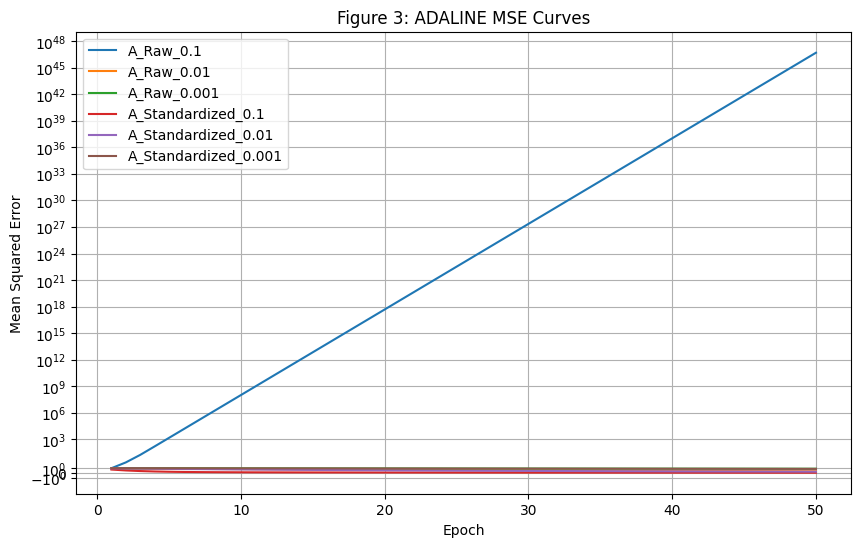

In [13]:

# Figure 3: ADALINE MSE Curves

plt.figure(figsize=(10, 6))

for name, model in experiments.items():
    if name.startswith("A_"):
        costs = np.array(model.cost_)

        plt.plot(
            range(1, len(costs) + 1),
            costs,
            label=name
        )

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Figure 3: ADALINE MSE Curves")
plt.yscale("symlog")
plt.legend()
plt.grid(True)
plt.show()


**Figure 3 interpretation:** Compare ADALINE squared-error convergence across three learning rates and both feature scales; rising cost suggests instability.

### Model Selection Criteria

The final models will be selected using training results only, without inspecting test-set performance.

For Perceptron, the configuration with the fewest misclassified training samples after 50 epochs will be selected.

For ADALINE, the configuration with the lowest finite final training MSE after 50 epochs will be selected. Divergent runs will be excluded.

If configurations tie, the standardized configuration will be preferred, followed by the smaller learning rate where applicable.

The test set will be reserved for the final evaluation.

In [14]:

# Select final models using training results only

p_runs = results_df[
    results_df["Model"] == "Perceptron"
].copy()

p_runs["Standardized"] = (
    p_runs["Run"] == "P2_Standardized"
)

best_p = p_runs.sort_values(
    ["Final Training Error", "Standardized"],
    ascending=[True, False]
).iloc[0]["Run"]

a_runs = results_df[
    (results_df["Model"] == "ADALINE") &
    (results_df["Status"] == "Completed") &
    np.isfinite(results_df["Final MSE"])
].copy()

a_runs["Standardized"] = (
    a_runs["Run"].str.contains("Standardized")
)

if a_runs.empty:
    raise RuntimeError("No valid ADALINE run found")

best_a = a_runs.sort_values(
    ["Final MSE", "Standardized", "Learning Rate"],
    ascending=[True, False, True]
).iloc[0]["Run"]

best_perceptron = experiments[best_p]
best_adaline = experiments[best_a]

print("Best Perceptron:", best_p)
print("Best ADALINE:", best_a)


Best Perceptron: P2_Standardized
Best ADALINE: A_Standardized_0.1


### Task 5: Experiment Interpretation

The experiments compare the effects of feature scaling and learning rate on Perceptron and ADALINE.

Perceptron is evaluated using the number of misclassified training samples after each epoch, while ADALINE is evaluated using mean squared error.

The final configurations are selected according to the predefined training criteria. The test data has not been used for model selection.

In [15]:

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)

# Use the correct feature version for each model
X_p = X_test_std if "Standardized" in best_p else X_test
X_a = X_test_std if "Standardized" in best_a else X_test

y_pred_p = best_perceptron.predict(X_p)
y_pred_a = best_adaline.predict(X_a)

evaluation = []

for name, predictions in [
    ("Perceptron", y_pred_p),
    ("ADALINE", y_pred_a)
]:
    evaluation.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    })

evaluation_df = pd.DataFrame(evaluation)
print("Table 2: Held-out test metrics")
display(evaluation_df)


Table 2: Held-out test metrics


,Model,Accuracy,Precision,Recall,F1 Score
0,Perceptron,1.0,1.0,1.0,1.0
1,ADALINE,1.0,1.0,1.0,1.0


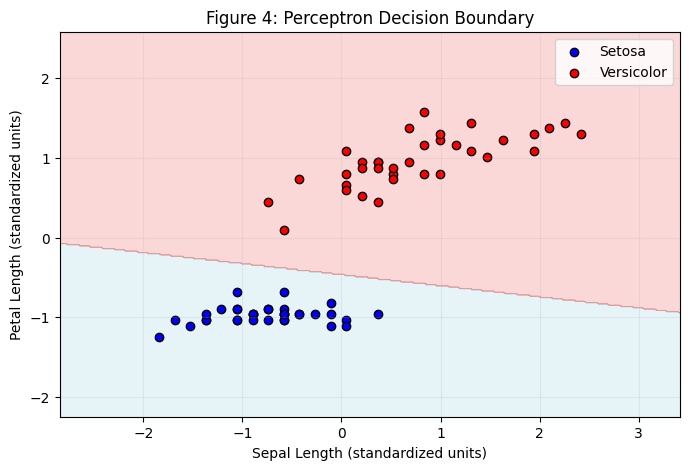

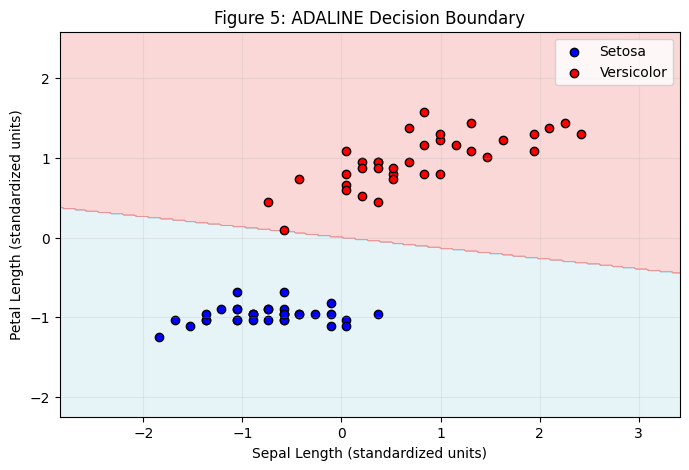

In [16]:
from matplotlib.colors import ListedColormap

def plot_decision_boundary(model, X, y, figure_num, model_name, standardized):
    x_min, x_max = X[:, 0].min()-1, X[:, 0].max()+1
    y_min, y_max = X[:, 1].min()-1, X[:, 1].max()+1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid).reshape(xx.shape)
    plt.figure(figsize=(8, 5))
    plt.contourf(xx, yy, Z, alpha=0.3, cmap=ListedColormap(["lightblue", "lightcoral"]))
    for label, name, color in [(-1, "Setosa", "blue"), (1, "Versicolor", "red")]:
        plt.scatter(X[y == label, 0], X[y == label, 1], label=name, c=color, edgecolors="black")
    unit = "standardized units" if standardized else "cm"
    plt.xlabel(f"Sepal Length ({unit})")
    plt.ylabel(f"Petal Length ({unit})")
    plt.title(f"Figure {figure_num}: {model_name} Decision Boundary")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()

plot_decision_boundary(best_perceptron, X_train_std if "Standardized" in best_p else X_train,
                       y_train, 4, "Perceptron", "Standardized" in best_p)
plot_decision_boundary(best_adaline, X_train_std if "Standardized" in best_a else X_train,
                       y_train, 5, "ADALINE", "Standardized" in best_a)

**Figures 4–5 interpretation:** Both models learn linear boundaries, but their different optimization rules can place the boundaries differently.

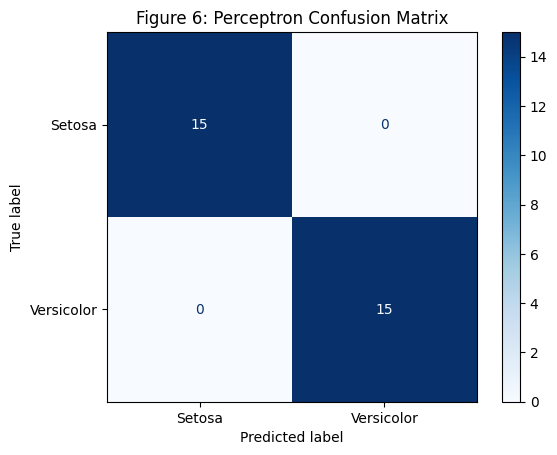

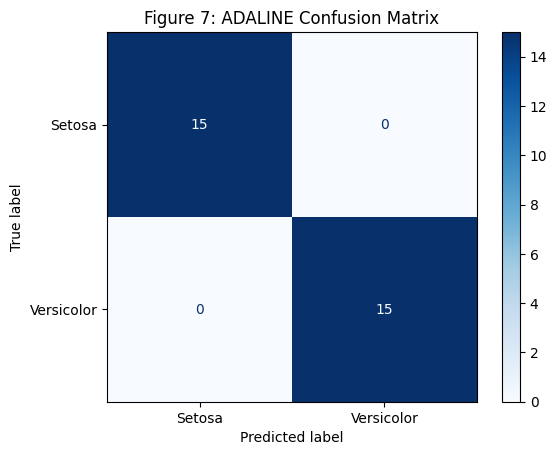

In [17]:

for name, predictions, figure_num in [
    ("Perceptron", y_pred_p, 6),
    ("ADALINE", y_pred_a, 7)
]:
    cm = confusion_matrix(
        y_test, predictions, labels=[-1, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Setosa", "Versicolor"]
    )

    disp.plot(cmap="Blues")
    plt.title(f"Figure {figure_num}: {name} Confusion Matrix")
    plt.show()


**Figures 6–7 interpretation:** The confusion matrices show the number of correctly and incorrectly classified Setosa and Versicolor test samples.

In [18]:

for name, model, X_eval, predictions in [
    ("Perceptron", best_perceptron, X_p, y_pred_p),
    ("ADALINE", best_adaline, X_a, y_pred_a)
]:
    print("\nModel:", name)
    print("Feature order: Sepal Length, Petal Length")
    print("Weights:", model.weights_)
    print("Bias:", model.bias_)

    correct = np.where(predictions == y_test)[0]
    incorrect = np.where(predictions != y_test)[0]

    if len(correct) > 0:
        i = correct[0]
        print("Correct sample:")
        print("True:", y_test[i],
              "Predicted:", predictions[i],
              "z:", model.net_input(X_eval[i]))

    if len(incorrect) > 0:
        i = incorrect[0]
        print("Incorrect sample:")
        print("True:", y_test[i],
              "Predicted:", predictions[i],
              "z:", model.net_input(X_eval[i]))
    else:
        print("No misclassified test samples.")



Model: Perceptron
Feature order: Sepal Length, Petal Length
Weights: [0.00595798 0.04291947]
Bias: 0.02
Correct sample:
True: -1 Predicted: -1 z: -0.037398205382253746
No misclassified test samples.

Model: ADALINE
Feature order: Sepal Length, Petal Length
Weights: [0.10920112 0.83342879]
Bias: 6.10305456965372e-16
Correct sample:
True: -1 Predicted: -1 z: -1.1036451808695638
No misclassified test samples.


### Task 6: Model Evaluation and Comparison

The selected Perceptron and ADALINE models were evaluated using the held-out test dataset.

Accuracy, precision, recall, and F1-score were calculated to assess classification performance. Decision-boundary plots and confusion matrices were also generated.

Both models produce linear decision boundaries, but their training objectives are different. Perceptron updates its parameters based on classification errors, whereas ADALINE minimizes squared error using continuous linear outputs.

Therefore, the two models can learn different weights, decision boundaries, and convergence curves even if they achieve identical test accuracy.

### Task 6: Evaluation Results and Interpretation

Both Perceptron and ADALINE achieved 100% accuracy, precision, recall, and F1-score on the test dataset.

Both models correctly classified all 30 test samples, with no misclassifications.

Although their classification performance was identical, the models use different learning rules. Perceptron updates its parameters based on classification errors, while ADALINE minimizes squared error using batch gradient descent.

Perfect accuracy on this small test set does not guarantee perfect performance on unseen or noisy sensor measurements.

In [19]:

# Task 7: Simulated Sensor Noise

assert "Standardized" in best_p and "Standardized" in best_a, "Noise study requires standardized-trained models; retrain on standardized inputs before proceeding."
noise_levels = [0.10, 0.25, 0.50]
noise_results = []

rng = np.random.RandomState(42)

# Both selected models use standardized features
for sigma in noise_levels:
    for repetition in range(30):
        noise = rng.normal(
            loc=0.0,
            scale=sigma,
            size=X_test_std.shape
        )

        X_noisy = X_test_std + noise

        for name, model in [
            ("Perceptron", best_perceptron),
            ("ADALINE", best_adaline)
        ]:
            predictions = model.predict(X_noisy)
            accuracy = accuracy_score(
                y_test, predictions
            )

            noise_results.append({
                "Model": name,
                "Noise Level": sigma,
                "Repetition": repetition + 1,
                "Accuracy": accuracy
            })

noise_df = pd.DataFrame(noise_results)

noise_summary = (
    noise_df.groupby(["Model", "Noise Level"])
    ["Accuracy"]
    .agg(["mean", "std"])
    .reset_index()
)

print("Table 3: Noise robustness summary (mean and SD over 30 repetitions)")
display(noise_summary)


Table 3: Noise robustness summary (mean and SD over 30 repetitions)


,Model,Noise Level,mean,std
0,ADALINE,0.10,1.000000,0.000000
1,ADALINE,0.25,0.982222,0.020960
2,ADALINE,0.50,0.972222,0.032851
3,Perceptron,0.10,1.000000,0.000000
4,Perceptron,0.25,0.992222,0.014339
5,Perceptron,0.50,0.955556,0.037481


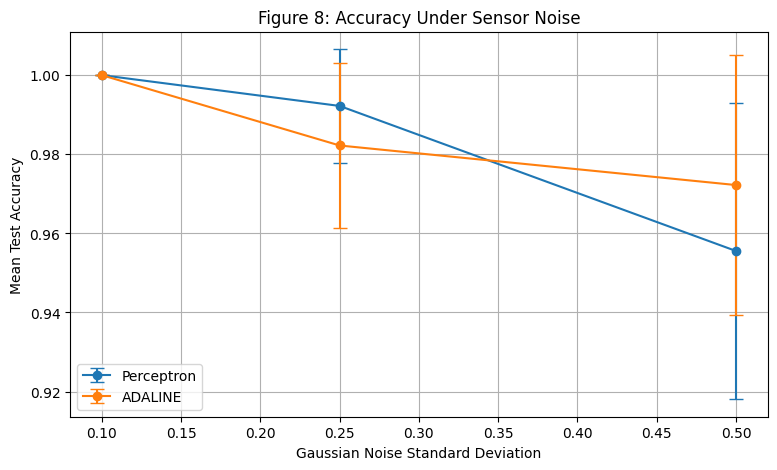

In [20]:

# Figure 8: Sensor Noise Robustness

plt.figure(figsize=(9, 5))

for model_name in ["Perceptron", "ADALINE"]:
    subset = noise_summary[
        noise_summary["Model"] == model_name
    ]

    plt.errorbar(
        subset["Noise Level"],
        subset["mean"],
        yerr=subset["std"],
        marker="o",
        capsize=5,
        label=model_name
    )

plt.xlabel("Gaussian Noise Standard Deviation")
plt.ylabel("Mean Test Accuracy")
plt.title("Figure 8: Accuracy Under Sensor Noise")
plt.legend()
plt.grid(True)
plt.show()


**Figure 8 interpretation:** Accuracy decreases with stronger perturbations; at σ=0.50, ADALINE had a higher mean accuracy in this experiment.

### Task 7: Sensor Noise Experiment

Gaussian noise with zero mean was added to the standardized test features at three standard deviations: 0.10, 0.25, and 0.50.

Each noise level was tested 30 times without retraining either model.

The mean accuracy and standard deviation were calculated to evaluate the robustness of Perceptron and ADALINE under simulated sensor measurement errors.

The models were trained using different objectives: Perceptron minimizes classification mistakes through its update rule, whereas ADALINE minimizes squared error. These differences may influence how their decision boundaries respond to noisy inputs.

### Task 7: Noise Robustness Results and Discussion

Both Perceptron and ADALINE achieved 100% mean accuracy at a noise standard deviation of 0.10.

At σ = 0.25, Perceptron achieved 99.22% mean accuracy, compared with 98.22% for ADALINE.

At σ = 0.50, ADALINE achieved 97.22% mean accuracy, outperforming Perceptron, which achieved 95.56%.

These results suggest that ADALINE was more robust at the highest tested noise level, while Perceptron performed slightly better at the intermediate level.

ADALINE minimizes squared error using continuous outputs, whereas Perceptron updates its weights based on classification errors. These learning objectives can produce different decision boundaries and sensitivities to noise.

However, the differences are relatively small, and this experiment alone is not sufficient to establish that either model is universally more robust.

### Task 8: Engineering Interpretation and Reproducibility

**1. Model Selection for Deployment**

For this binary plant-inspection problem, I would initially select ADALINE as the preferred model for deployment. Both Perceptron and ADALINE achieved 100% accuracy, precision, recall, and F1-score on the clean test dataset. However, their performance under simulated sensor noise was slightly different.

At the highest tested noise level (σ = 0.50), ADALINE achieved 97.22% mean accuracy, while Perceptron achieved 95.56%. This suggests that ADALINE may offer better robustness under stronger measurement noise in this particular experiment. Nevertheless, additional testing would be necessary before deployment.

**2. Limitations of Accuracy and Dataset Size**

Accuracy alone is not sufficient to evaluate a machine-learning model. A model may achieve high accuracy while still making important mistakes on particular classes or difficult measurements. Therefore, precision, recall, F1-score, and confusion matrices should also be considered.

The Iris dataset is relatively small, and this binary experiment uses only 100 samples from two flower species. The test set contains 30 samples, which limits confidence in how well the results generalize to real industrial environments. Real sensor measurements may contain more noise, missing values, unexpected conditions, and different distributions.

**3. Data Drift and Sensor Calibration**

Data drift occurs when the statistical properties of incoming measurements change over time. For example, changes in environmental conditions, equipment aging, or plant characteristics could affect the measurements collected by sensors.

Sensor calibration errors could introduce systematic measurement shifts. Such shifts may move observations across the learned decision boundary and increase classification errors. Therefore, regular calibration and data-quality checks would be necessary.

**4. Monitoring and Retraining**

Two important monitoring signals would be classification performance and changes in input-feature distributions.

First, accuracy or recall should be monitored using periodically verified inspection samples. A sustained decrease could indicate declining model reliability.

Second, the distributions of sepal length and petal length measurements should be compared with the original training data. Significant changes may indicate sensor problems or data drift.

A possible retraining trigger would be a sustained decrease in verified accuracy below 95%, after investigating measurement quality and confirming that the decline is not caused by a temporary sensor issue.

**5. Ethical and Operational Risk**

An important operational risk is making incorrect automated inspection decisions. Misclassifying a plant could result in unnecessary rejection or acceptance, potentially causing financial losses or reducing inspection reliability.

To reduce this risk, uncertain predictions should be reviewed by a human operator, particularly during the initial deployment period. The system should also maintain records of predictions, sensor measurements, and model versions for traceability.

**Conclusion**

Although both models performed perfectly on the clean test data, ADALINE showed slightly better robustness at the highest simulated noise level. I would therefore choose ADALINE as a provisional deployment candidate, while requiring further validation using larger datasets and real sensor measurements.

In [21]:

import sys
import numpy
import pandas
import matplotlib
import sklearn

print("Python:", sys.version)
print("NumPy:", numpy.__version__)
print("pandas:", pandas.__version__)
print("Matplotlib:", matplotlib.__version__)
print("scikit-learn:", sklearn.__version__)


Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
NumPy: 2.1.3
pandas: 2.2.3
Matplotlib: 3.10.0
scikit-learn: 1.6.1


## Optional Bonus (+10): Three-Class One-vs-Rest Extension

We extend our own `PerceptronScratch` to classify **all three Iris species** using **all four measurements** (cm). Each of three binary classifiers treats its target species as +1 and the remaining two as −1. The predicted class is the classifier with the largest linear net input (score). The 70/30 stratified split uses seed 42, and scaling is fitted on training data only. No ready-made classifier is used.

Three-class macro-F1: 0.8153
              precision    recall  f1-score   support

      setosa       0.75      1.00      0.86        15
  versicolor       0.82      0.60      0.69        15
   virginica       0.93      0.87      0.90        15

    accuracy                           0.82        45
   macro avg       0.83      0.82      0.82        45
weighted avg       0.83      0.82      0.82        45

Three-class confusion matrix:
 [[15  0  0]
 [ 5  9  1]
 [ 0  2 13]]


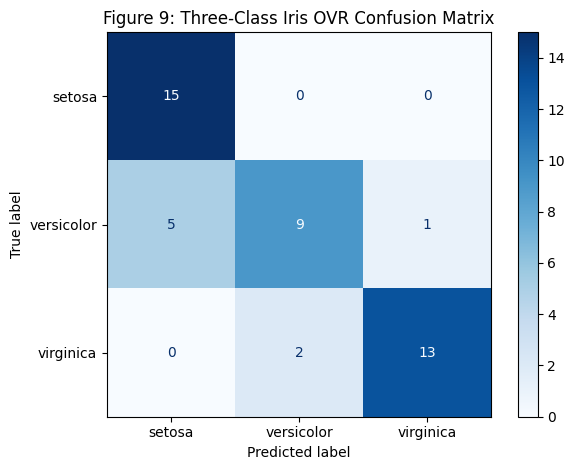

Hardest class pair(s) on this test split: [(np.str_('setosa'), np.str_('versicolor'))] | mutual misclassifications: 5
Binary-task test F1 (both models): 1.0 and 1.0


In [22]:
# Bonus: three-class One-vs-Rest built from our own PerceptronScratch
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

class PerceptronOVRScratch:
    """One-vs-rest multi-class wrapper using PerceptronScratch models."""
    def __init__(self, learning_rate=0.01, max_epochs=50, random_seed=42):
        self.learning_rate = learning_rate
        self.max_epochs = max_epochs
        self.random_seed = random_seed

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.models_ = []
        for cls in self.classes_:
            binary_y = np.where(y == cls, 1, -1)
            model = PerceptronScratch(
                learning_rate=self.learning_rate,
                max_epochs=self.max_epochs,
                random_seed=self.random_seed
            )
            model.fit(X, binary_y)
            self.models_.append(model)
        return self

    def decision_function(self, X):
        return np.column_stack([model.net_input(X) for model in self.models_])

    def predict(self, X):
        scores = self.decision_function(X)
        return self.classes_[np.argmax(scores, axis=1)]

# The same Iris data source already loaded earlier as 'iris' is used here.
from sklearn.datasets import load_iris
iris = load_iris()
X_all = np.asarray(iris.data, dtype=float)  # four features, centimeters
y_all = np.asarray(iris.target, dtype=int) # three classes
species_names = list(iris.target_names)

X_train_3, X_test_3, y_train_3, y_test_3 = train_test_split(
    X_all, y_all, test_size=0.30, random_state=42, stratify=y_all
)
scaler_3 = StandardScaler()
X_train_3_std = scaler_3.fit_transform(X_train_3)
X_test_3_std = scaler_3.transform(X_test_3)

ovr_model = PerceptronOVRScratch(learning_rate=0.01, max_epochs=50, random_seed=42)
ovr_model.fit(X_train_3_std, y_train_3)
y_pred_3 = ovr_model.predict(X_test_3_std)

bonus_macro_f1 = f1_score(y_test_3, y_pred_3, average='macro')
bonus_cm = confusion_matrix(y_test_3, y_pred_3, labels=[0, 1, 2])
print(f"Three-class macro-F1: {bonus_macro_f1:.4f}")
print(classification_report(y_test_3, y_pred_3, target_names=species_names, zero_division=0))
print("Three-class confusion matrix:\n", bonus_cm)

disp = ConfusionMatrixDisplay(confusion_matrix=bonus_cm, display_labels=species_names)
disp.plot(cmap='Blues', values_format='d')
plt.title('Figure 9: Three-Class Iris OVR Confusion Matrix')
plt.tight_layout()
plt.show()

# Hardest pair = largest number of mutual confusions between two classes.
pair_confusions = []
for i in range(3):
    for j in range(i+1, 3):
        pair_confusions.append((bonus_cm[i, j] + bonus_cm[j, i], i, j))
max_confusion = max(row[0] for row in pair_confusions)
if max_confusion == 0:
    print('No class-pair confusion on this test set; no empirically hardest pair can be identified.')
else:
    hardest = [(species_names[i], species_names[j]) for n, i, j in pair_confusions if n == max_confusion]
    print('Hardest class pair(s) on this test split:', hardest,
          '| mutual misclassifications:', max_confusion)
print('Binary-task test F1 (both models):',
      f1_score(y_test, y_pred_p), 'and', f1_score(y_test, y_pred_a))

### Bonus interpretation

The binary task distinguishes **setosa** from **versicolor** using two features and reached an F1-score of 1.00 on the held-out test set. The three-class extension adds **virginica** and uses all four features; its macro-F1 averages F1 across all three species, giving each class equal importance. The confusion matrix identifies which pairs were mistaken for one another on the three-class test set. If no off-diagonal errors appear, the test results cannot establish a hardest pair; it would be inappropriate to claim one from these results alone. This comparison is not controlled for number of classes or number of features, so differences cannot be attributed solely to the algorithm.

**Observed results:** On this seeded test split, the OVR model achieved macro-F1 = **0.8153** and accuracy = **0.8222** (37/45 correct). The largest observed mutual confusion was **setosa vs versicolor**, with 5 errors (5 versicolor samples predicted as setosa). The binary test achieved F1 = **1.00** on 30 samples. The three-class task is harder here, but it also uses four rather than two features, so these are not directly equivalent test conditions. The result is specific to this training configuration and split.